In [57]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [58]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

And we get backend information.

In [70]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
# desired_duration = 120  # dt
desired_duration = 128 # dt, apl pulses

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 128)

Then we load our robust gateset.

In [82]:
# pico_a = ps.from_csv(
#     "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
# )
pico_a = ps.from_csv(
    "../pico-pulses/apl-pulses/x_gates.csv"
)
pico_gates = {key: row for key, row in zip(["x1", "x2"], pico_a)}

In [83]:
len(pico_gates["x1"]), len(pico_gates["x2"])

(128, 128)

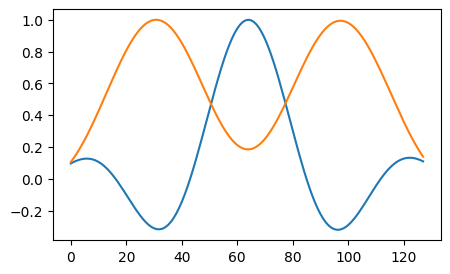

In [115]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

In [85]:
np.trapz(pico_gates["x1"], dx=dt), np.trapz(pico_gates["x2"], dx=dt)

(8.810458407220983, 38.473189703029895)

And we define a Guassian gateset to which we are going to compare.

In [63]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

The maximum aplitude allowed by qiskit pulse is the `amp` factor times the amplitude of the signal we are sending.

In [86]:
signal = pico_gates["x1"]
x1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

# signal = pico_gates["sx1"]
# sx1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

# print(x1_max, sx1_max)
# print(1 / x1_max, 1 / sx1_max)

print(x1_max)
print(1 / x1_max)

1.0
1.0


In [87]:
signal = pico_gates["x2"]
x2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

# signal = pico_gates["sx2"]
# sx2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

# print(x2_max, sx2_max)
# print(1 / x2_max, 1 / sx2_max)

print(x2_max)
print(1 / x2_max)

1.0
1.0


So we can bump up the `drive_amps` closer to -3 and 3.

## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [90]:
qubit0, qubit1 = 0, 1
qubit2, qubit3 = 2, 3
qubit4, qubit5 = 4, 5

In [147]:
drive_amps_1 = np.linspace(-1, 1, 50)
drive_amps_2 = np.linspace(-0.5, 0.5, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [153]:
def get_schedules(signal, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"rabi_sched", backend=backend) as sched:
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, "custom", amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [154]:
robust_x1_schedules = get_schedules(pico_gates["x1"], qubit0, drive_amps_1)

We do the same for the Gaussian pulses.

In [155]:
gaussian_x1_schedules = get_schedules(default_gates["x1"].samples, qubit0, drive_amps_1)

We can use the schedules to create circuits that we can run to IBM.

In [156]:
num_qubits = backend.num_qubits
num_qubits

127

In [157]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for i, schedule in enumerate(schedules):
        gate = qk.circuit.Gate(f"x_rabi", 1, [])
        cr = qk.ClassicalRegister(1, name="c")
        qr = qk.QuantumRegister(num_qubits, name="q")
        qc = qk.QuantumCircuit(qr, cr, name=f"schedule")
        qc.append(gate, [qubit])
        qc.measure(qubit, cr[0])
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [158]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x1_circuits[0].draw(idle_wires=False)

┌────────┐┌─┐
q_0: ┤ x_rabi ├┤M├
     └────────┘└╥┘
c: 1/═══════════╩═
                0

We can parallelize our calibration by running circuits that act on different qubits at the same time. So, we can calibrate both x gates in parallel, and both sx gates in parallel. We can also do more qubit pairs.

In [159]:
def construct_parallel_circuits(qubits: list[int], signals, drive_amps_list: list[list[float]], num_qubits: int):
    assert len(qubits) == len(signals)

    qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(len(drive_amps_list[0]))]
    crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(len(drive_amps_list[0]))]
    qcs = [qk.QuantumCircuit(qrs[i], crs[i]) for i in range(len(drive_amps_list[0]))]

    for i, (qubit, signal) in enumerate(zip(qubits, signals)):
        schedules = get_schedules(signal, qubit, drive_amps_list[i])
        circuits = get_circuits_from_scheds(schedules, num_qubits, qubit)
        
        for j, (qc, circuit) in enumerate(zip(qcs, circuits)):
            qc.append(circuit, qargs=qrs[j], cargs=(crs[j][i],))

            # have to add calibrations to new circuit
            gate = qk.circuit.Gate("x_rabi", 1, [])
            qc.add_calibration(gate, (qubit,), schedules[j])

    return [qc.decompose() for qc in qcs]

In [160]:
qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5]
x_signals = [pico_gates["x1"], pico_gates["x2"]] * 3
# sx_signals = [pico_gates["sx1"], pico_gates["sx2"]] * 3
drive_amps_list = [drive_amps_1, drive_amps_2] * 3

x_parallel_circuits = construct_parallel_circuits(qubits, x_signals, drive_amps_list, num_qubits)
# sx_parallel_circuits = construct_parallel_circuits(qubits, sx_signals, drive_amps_list, num_qubits)

In [161]:
x_parallel_circuits[3].draw(idle_wires=False)

┌────────┐┌─┐               
q_0: ┤ x_rabi ├┤M├───────────────
     ├────────┤└╥┘┌─┐            
q_1: ┤ x_rabi ├─╫─┤M├────────────
     ├────────┤ ║ └╥┘┌─┐         
q_2: ┤ x_rabi ├─╫──╫─┤M├─────────
     ├────────┤ ║  ║ └╥┘┌─┐      
q_3: ┤ x_rabi ├─╫──╫──╫─┤M├──────
     ├────────┤ ║  ║  ║ └╥┘┌─┐   
q_4: ┤ x_rabi ├─╫──╫──╫──╫─┤M├───
     ├────────┤ ║  ║  ║  ║ └╥┘┌─┐
q_5: ┤ x_rabi ├─╫──╫──╫──╫──╫─┤M├
     └────────┘ ║  ║  ║  ║  ║ └╥┘
c: 6/═══════════╩══╩══╩══╩══╩══╩═
                0  1  2  3  4  5

So, as you can see above, we parallelize the rough calibration by running circuits of the form above (we omit idle wires in the drawing to save space).

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [163]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: csmvvwf0c2pg008byesg


In [164]:
sampler = Sampler(backend=backend, session=session)
sampler.options.experimental = {"execution": {"fast_parametric_update": False}} # make sure pulse instructions are sent correctly

In [165]:
num_shots_per_point = 1024

In [166]:
x_parallel_jobs = sampler.run(x_parallel_circuits, shots=num_shots_per_point)
# sx_parallel_jobs = sampler.run(sx_parallel_circuits, shots=num_shots_per_point)

In [167]:
x_parallel_jobs.job_id(), # sx_parallel_jobs.job_id()

('csmvvxf0c2pg008byev0',)

In [180]:
x_parallel_jobs.status(), # sx_parallel_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,)

In [182]:
x_parallel_jobs = service.job("csmvvxf0c2pg008byev0")
# sx_parallel_jobs = service.job("crmrp60gz13g008sqkxg")

We define the functions that will help us analyze the calibration data.

In [183]:
def get_qubit_one_counts(counts, qubit, num_qubits):
    total = 0
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] == "1": # because of little-endian
            total += val
    return total

In [184]:
def get_rabi_values(job, shots, qubits):
    rabi_values = [[] for _ in range(len(qubits))] # each list element is the data for a single qubit
    result = job.result()
    for i in range(len(result)):
        counts = result[i].data.c.get_counts()
        for j in range(len(qubits)):
            rabi_values[j].append(get_qubit_one_counts(counts, j, len(qubits)) / shots)
    return rabi_values

In [185]:
x_rabi_values = get_rabi_values(x_parallel_jobs, num_shots_per_point, qubits)
# sx_rabi_values = get_rabi_values(sx_parallel_jobs, num_shots_per_point, qubits)

In [186]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [199]:
def get_drive_period(
    rabi_values: list[float], 
    drive_amps: list[float], 
    factor: int,
    gate_name: str = "",
    plot: bool = False, 
    qubit: int = 0,
    amplitude_max: float = 1,
    normal_params: bool = True,
):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(baseline_remove(rabi_values))
    
    starting_params = [1, 1, 1.5, 0.5] if normal_params else [1, 1, 0.3, 0.5]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, A, B, drive_period, phi: (
            A * np.cos(2 * np.pi * x / drive_period - phi) + B
        ),
        starting_params,
    )

    drive_period = fit_params[2]  # get period of rabi oscillation
    
    if plot:
        plot_amps = amplitude_max * np.array(drive_amps)
        plt.scatter(plot_amps, rabi_values, marker="x", color="black")
        plt.plot(plot_amps, y_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1 (baseline removed)")
        plt.title(f"{gate_name} calibration on qubit {qubit}")
        plt.show()

    return drive_period / factor

And we get the estimated amplitudes.

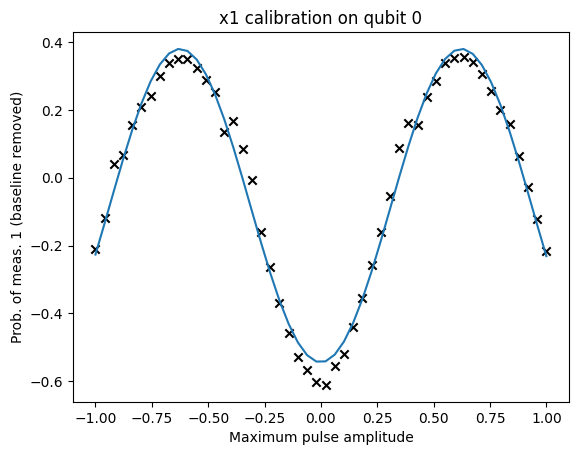

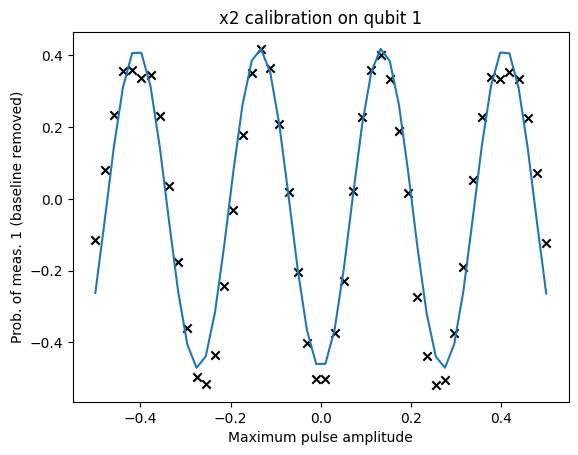

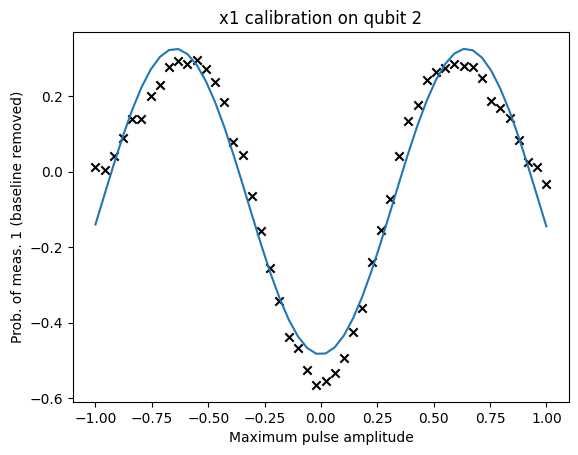

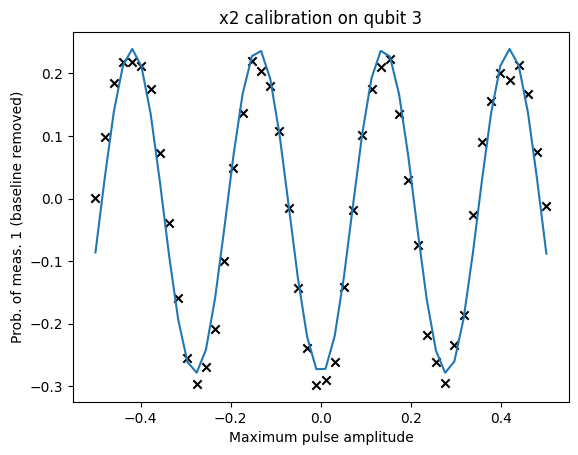

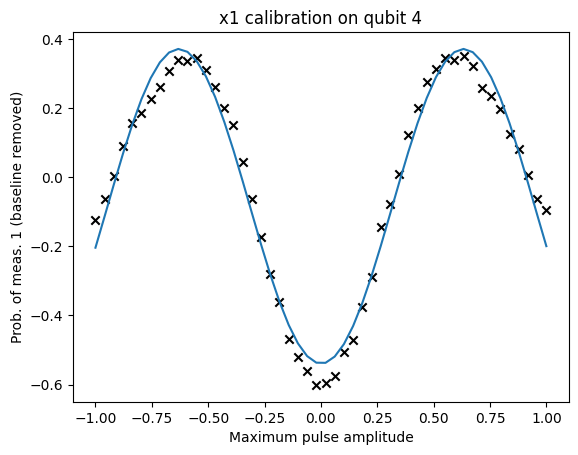

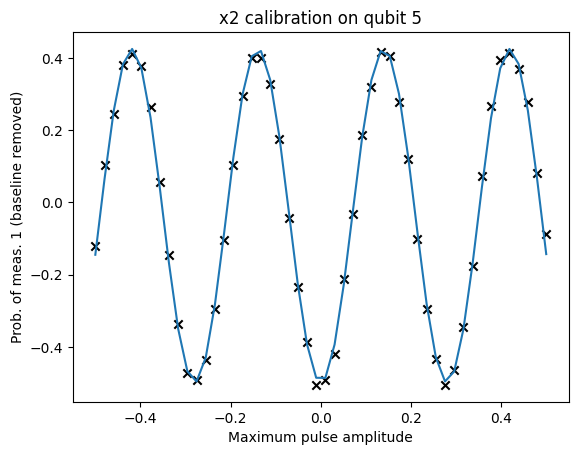

In [200]:
x_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values)):
    x_rough_amps.append(get_drive_period(
        rabi,
        drive_amps_list[i],
        2,
        gate_name=f"x{i % 2 + 1}",
        plot=True, 
        qubit=qubit, 
        amplitude_max= x1_max if i % 2 == 0 else x2_max,
        normal_params=True if i % 2 == 0 else False,  
    ))

In [201]:
# sx_rough_amps = []
# for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values)):
#     sx_rough_amps.append(get_drive_period(
#         rabi, 
#         drive_amps_list[i], 
#         4,
#         gate_name=f"sx{i % 2 + 1}", 
#         plot=True, 
#         qubit=qubit,
#         amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
#         normal_params=True if i % 2 == 0 else False,  
#     ))


In [202]:
for i, (qubit, period) in enumerate(zip(qubits, x_rough_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate period: {period}")

Qubit 0 x1 gate period: 0.6238690917117397
Qubit 1 x2 gate period: 0.13594768633070325
Qubit 2 x1 gate period: 0.6451961611295679
Qubit 3 x2 gate period: 0.1395365046104916
Qubit 4 x1 gate period: 0.6316046962358665
Qubit 5 x2 gate period: 0.13986064786157537


In [151]:
# for i, (qubit, period) in enumerate(zip(qubits, sx_rough_amps)):
#     print(f"Qubit {qubit} sx{i % 2 + 1} gate period: {period}")

In [152]:
# for i, (x_period, sx_period) in enumerate(zip(x_rough_amps, sx_rough_amps)):
#     print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_period / x_period)

## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [203]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [204]:
def get_fine_experiment(sched, qubit: int, gate: str, backend, x_gate: bool = True):
    inst_map = qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    if x_gate:
        exp = qk_e.library.FineXAmplitude((qubit,), backend)
    else:
        exp = qk_e.library.FineSXAmplitude((qubit,), backend)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

We know construct the fine amplitude experiments.

In [206]:
fine_x_experiments = []
fine_sx_experiments = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals)):
    sched = build_schedule(signal, qubit, x_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments.append(exp)

# for i, (qubit, signal) in enumerate(zip(qubits, sx_signals)):
#     sched = build_schedule(signal, qubit, sx_rough_amps[i])
#     exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
#     fine_sx_experiments.append(exp)

And parallelize them like we did with the rough calibration circuits.

In [208]:
x_num_circuits = len(fine_x_experiments[0].circuits())
x_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits = [qk.QuantumCircuit(x_qrs[i], x_crs[i]) for i in range(x_num_circuits)]

# sx_num_circuits = len(fine_sx_experiments[0].circuits())
# sx_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
# sx_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
# fine_sx_circuits = [qk.QuantumCircuit(sx_qrs[i], sx_crs[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits = fine_x_experiments[i].circuits()
    # sx_circuits = fine_sx_experiments[i].circuits()

    x_schedule = build_schedule(x_signals[i], qubit, x_rough_amps[i])
    # sx_schedule = build_schedule(sx_signals[i], qubit, sx_rough_amps[i])

    for j in range(x_num_circuits):
        fine_x_circuits[j].append(x_circuits[j], qargs=(x_qrs[j][qubit],), cargs=(x_crs[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits[j].add_calibration(gate, (qubit,), x_schedule)
        
    # for j in range(sx_num_circuits):
    #     fine_sx_circuits[j].append(sx_circuits[j], qargs=(sx_qrs[j][qubit],), cargs=(sx_crs[j][i],))
    #     gate = qk.circuit.library.SXGate()
    #     fine_sx_circuits[j].add_calibration(gate, (qubit,), sx_schedule)

fine_x_circuits = [circuit.decompose() for circuit in fine_x_circuits]
# fine_sx_circuits = [circuit.decompose() for circuit in fine_sx_circuits]

In [209]:
fine_x_circuits[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐┌─┐               
q_0: ┤ √X ├┤ X ├┤ X ├┤M├───────────────
     ├────┤├───┤├───┤└╥┘┌─┐            
q_1: ┤ √X ├┤ X ├┤ X ├─╫─┤M├────────────
     ├────┤├───┤├───┤ ║ └╥┘┌─┐         
q_2: ┤ √X ├┤ X ├┤ X ├─╫──╫─┤M├─────────
     ├────┤├───┤├───┤ ║  ║ └╥┘┌─┐      
q_3: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫─┤M├──────
     ├────┤├───┤├───┤ ║  ║  ║ └╥┘┌─┐   
q_4: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫─┤M├───
     ├────┤├───┤├───┤ ║  ║  ║  ║ └╥┘┌─┐
q_5: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫──╫─┤M├
     └────┘└───┘└───┘ ║  ║  ║  ║  ║ └╥┘
c: 6/═════════════════╩══╩══╩══╩══╩══╩═
                      0  1  2  3  4  5

In [210]:
fine_x_circuits[3].calibrations["x"][((1,), ())] # we can check calibrations were added 

ScheduleBlock(Play(Waveform(array([0.01604086+0.j, 0.01943656+0.j, 0.02310915+0.j, 0.0270491 +0.j,
       0.03124351+0.j, 0.03567638+0.j, 0.04032865+0.j, 0.04517828+0.j,
       0.05020039+0.j, 0.05536745+0.j, 0.06064947+0.j, 0.06601425+0.j,
       0.07142768+0.j, 0.07685399+0.j, 0.08225612+0.j, 0.08759608+0.j,
       0.09283527+0.j, 0.09793493+0.j, 0.10285648+0.j, 0.10756193+0.j,
       0.1120143 +0.j, 0.11617801+0.j, 0.12001923+0.j, 0.12350632+0.j,
       0.12661013+0.j, 0.12930435+0.j, 0.13156584+0.j, 0.13337489+0.j,
       0.13471546+0.j, 0.13557541+0.j, 0.13594668+0.j, 0.13582538+0.j,
       0.13521193+0.j, 0.13411106+0.j, 0.13253187+0.j, 0.13048773+0.j,
       0.12799622+0.j, 0.125079  +0.j, 0.12176164+0.j, 0.1180734 +0.j,
       0.11404697+0.j, 0.10971821+0.j, 0.1051258 +0.j, 0.10031092+0.j,
       0.09531686+0.j, 0.09018859+0.j, 0.0849724 +0.j, 0.07971544+0.j,
       0.07446529+0.j, 0.06926951+0.j, 0.06417518+0.j, 0.05922848+0.j,
       0.05447428+0.j, 0.04995566+0.j, 0.04571356

And we submit this parallel jobs.

In [211]:
num_shots = 4000 # number extracted from non-parallelized experiments

In [212]:
x_fine_jobs = sampler.run(fine_x_circuits, shots=num_shots)
# sx_fine_jobs = sampler.run(fine_sx_circuits, shots=num_shots)

In [213]:
x_fine_jobs.job_id(), # sx_fine_jobs.job_id()

('csmx8gj0c2pg008bykz0',)

In [218]:
x_fine_jobs.status(), # sx_fine_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,)

In [219]:
x_fine_jobs = service.job("csmx8gj0c2pg008bykz0")
# sx_fine_jobs = service.job("crmrq74mevsg008435y0")

To get the experiment results, we have to extract the individual counts for each qubit and experiment, and then put it back together in a way that the experiment framework is able to process it. This is quite complicated and done in the next few cells.

In [220]:
def get_qubit_counts(counts, qubit, num_qubits):
    qubit_counts = {}
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] in qubit_counts:
            qubit_counts[key[num_qubits - qubit - 1]] += val
        else:
            qubit_counts[key[num_qubits - qubit - 1]] = val
    return qubit_counts    

In [221]:
fine_x_metadata = []
for i in range(x_num_circuits):
    fine_x_metadata.append(fine_x_experiments[0].circuits()[i].metadata)

# fine_sx_metadata = []
# for i in range(sx_num_circuits):
#     fine_sx_metadata.append(fine_sx_experiments[0].circuits()[i].metadata)

In [222]:
def reconstruct_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result.data.c.get_counts(), qubit, num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [224]:
fine_x_exp_datas = reconstruct_data(
    experiments=fine_x_experiments,
    job=x_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata,
)

# fine_sx_exp_datas = reconstruct_data(
#     experiments=fine_sx_experiments,
#     job=sx_fine_jobs,
#     qubits=qubits,
#     shots=num_shots,
#     metadata=fine_sx_metadata,
# )

In [225]:
def get_fine_amplitude_estimation(data, target_angle: float):
    dtheta = data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [226]:
x_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas]
x_fine_amps = [x_rough_amps[i] * ratio for i, ratio in enumerate(x_fine_ratios)]

# sx_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas]
# sx_fine_amps = [sx_rough_amps[i] * ratio for i, ratio in enumerate(sx_fine_ratios)]

Qubit 0 pulse x1


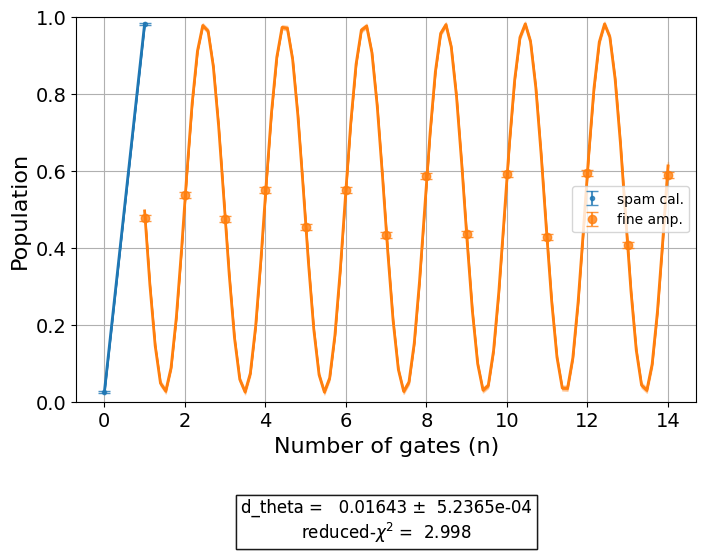

In [227]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 1 pulse x2


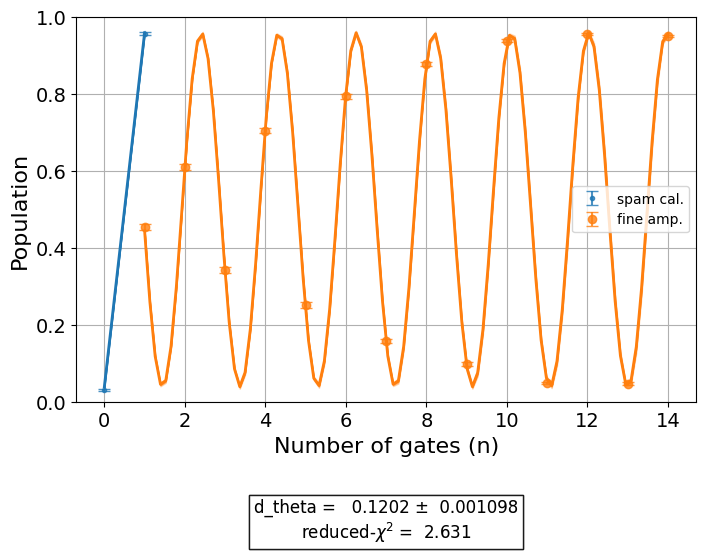

In [228]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 2 pulse x1


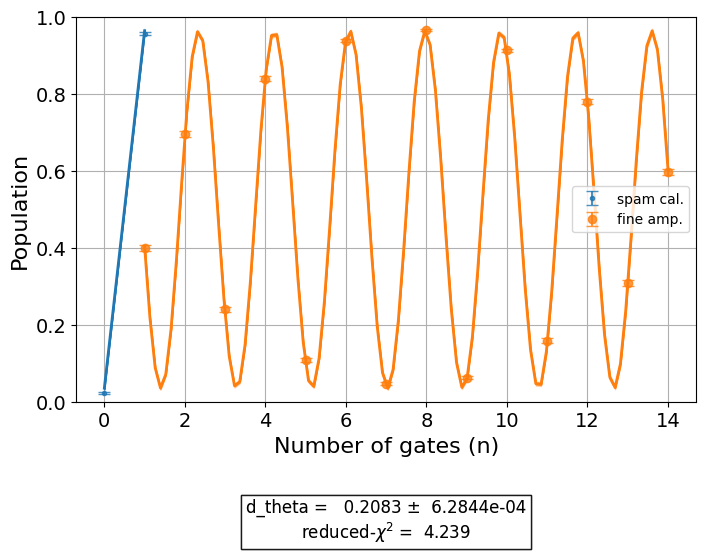

In [229]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 3 pulse x2


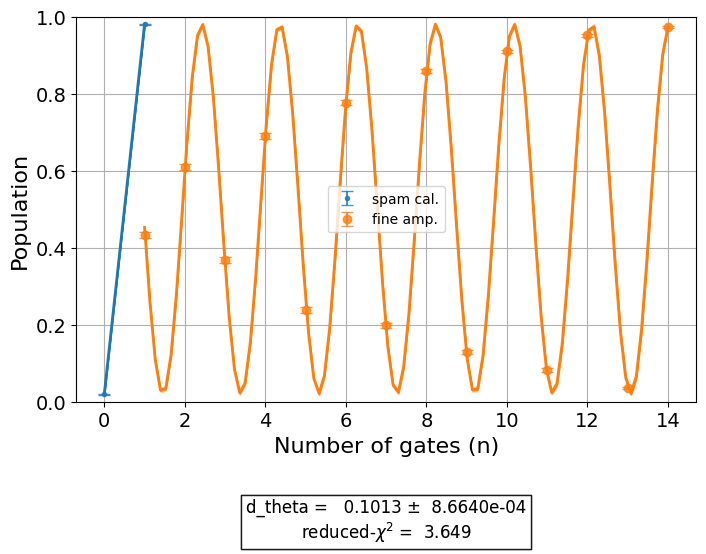

In [230]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 4 pulse x1


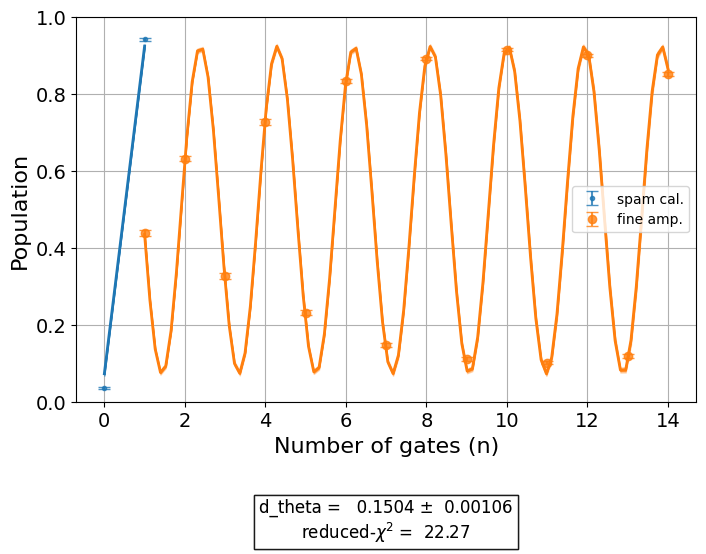

In [231]:
qubit_index = 4
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 5 pulse x2


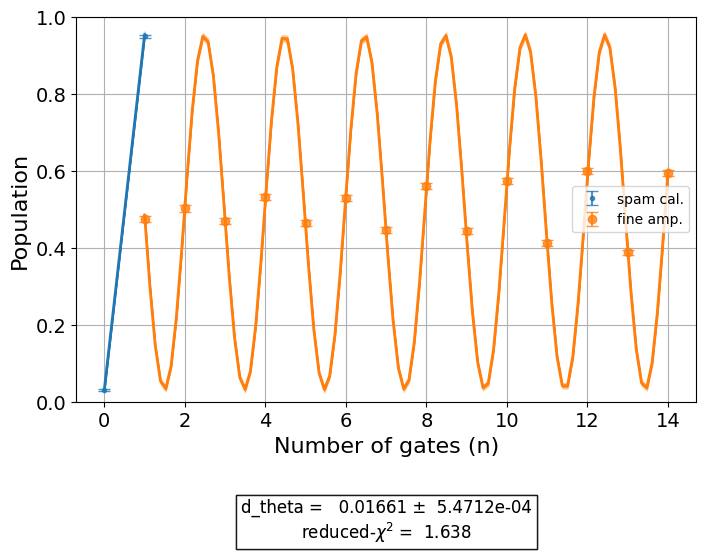

In [259]:
qubit_index = 5
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

In [232]:
# qubit_index = 0
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [233]:
# qubit_index = 1
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [234]:
# qubit_index = 2
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [237]:
# qubit_index = 3
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [235]:
# qubit_index = 4
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [236]:
# qubit_index = 5
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

We can check the amplitude ratios again after the fine calibration.

In [238]:
for i, (qubit, amp) in enumerate(zip(qubits, x_fine_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amplitude: {amp}")

Qubit 0 x1 gate amplitude: 0.6174101794508974
Qubit 1 x2 gate amplitude: 0.12628174872203493
Qubit 2 x1 gate amplitude: 0.569654647046928
Qubit 3 x2 gate amplitude: 0.13108380127371708
Qubit 4 x1 gate amplitude: 0.5764019807519943
Qubit 5 x2 gate amplitude: 0.13839693509262982


In [239]:
# for i, (qubit, amp) in enumerate(zip(qubits, sx_fine_amps)):
#     print(f"Qubit {qubit} sx{i % 2 + 1} gate amplitude: {amp}")

In [240]:
# for i, (x_amp, sx_amp) in enumerate(zip(x_fine_amps, sx_fine_amps)):
#     print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_amp / x_amp)

## XYXY Sequences

In [273]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])
# fine_q0_sx1 = build_schedule(pico_gates["sx1"], qubits[2], sx_fine_amps[2])
# fine_q1_sx2 = build_schedule(pico_gates["sx2"], qubits[3], sx_fine_amps[3])

In [274]:
def xyxy_sequence(n: int, q0: int, q1: int, schedules = None):
    qc = qk.QuantumCircuit(2)
    qc.sx(0)
    qc.sx(1)
    for _ in range(n):
        qc.x(0)
        qc.y(0)
        qc.x(0)
        qc.y(0)
        qc.x(1)
        qc.y(1)
        qc.x(1)
        qc.y(1)
    qc.sx(0)
    qc.sx(1)
    qc.measure_all()

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])
        # sx_gate = qk.circuit.library.SXGate()
        # qc.add_calibration(sx_gate, (q0,), schedules[2])
        # qc.add_calibration(sx_gate, (q1,), schedules[3])

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [275]:
# example = xyxy_sequence(1, qubits[2], qubits[3], [fine_q0_x1, fine_q1_x2, fine_q0_sx1, fine_q1_sx2])
example = xyxy_sequence(1, qubits[0], qubits[1], [fine_q0_x1, fine_q1_x2])
example.draw()

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐ ░ ┌─┐   
   q_0: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░─┤M├───
        ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤ ░ └╥┘┌─┐
   q_1: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░──╫─┤M├
        └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘ ░  ║ └╥┘
meas: 2/══════════════════════════════════════════════════════╩══╩═
                                                              0  1

In [276]:
lengths = list(range(1, 401, 4))
# dd_circuits_robust = [xyxy_sequence(i, qubits[2], qubits[3], [fine_q0_x1, fine_q1_x2, fine_q0_sx1, fine_q1_sx2]) for i in lengths]
dd_circuits_robust = [xyxy_sequence(i, qubits[0], qubits[1], [fine_q0_x1, fine_q1_x2]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, qubits[0], qubits[1]) for i in lengths]

In [277]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [315]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id()

('csmxdtzea560008fcsw0', 'csmxdvq1k2e0008p3a9g')

In [316]:
dd_jobs_robust.status(), dd_jobs_default.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [307]:
dd_jobs_robust = service.job("csmxdtzea560008fcsw0")
dd_jobs_default = service.job("csmxdvq1k2e0008p3a9g")

In [317]:
robust_results = dd_jobs_robust.result()
robust_counts = []
for result in robust_results:
    robust_counts.append(result.data.meas.get_counts())

default_results = dd_jobs_default.result()
default_counts = []
for result in default_results:
    default_counts.append(result.data.meas.get_counts())

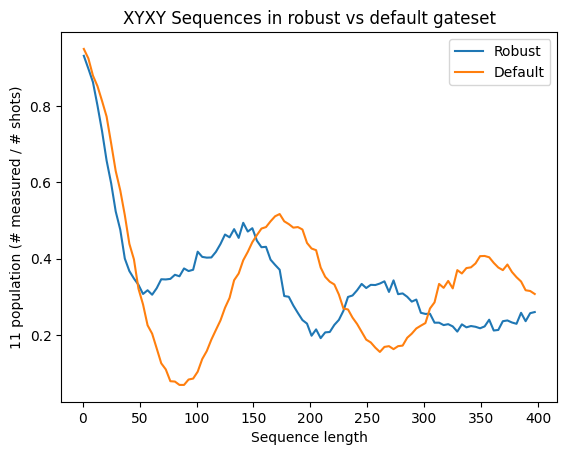

In [318]:
robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
default_11 = [count.get("11", 0) / 2048 for count in default_counts]

plt.plot(lengths, robust_11, label="Robust")
plt.plot(lengths, default_11, label="Default")
plt.xlabel("Sequence length")
plt.ylabel("11 population (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

## Parallel sequence of `x` gates

Now, we are going to choose one of the pairs we calibrated, and run circuits of parallel `x` gates of increasing length.

In [261]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])

In [291]:
def build_parallel_sequence(num_qubits: int, q0: int, q1: int,  length: int, schedules: list[qk.pulse.Schedule] = None):
    qr = qk.QuantumRegister(num_qubits, "q")
    cr = qk.ClassicalRegister(2, "c")
    qc = qk.QuantumCircuit(qr, cr)
    
    qc.reset(q0)
    qc.reset(q1)
    for _ in range(length + 1):
        qc.x(q0)
        qc.x(q1)
    qc.measure(q0, cr[0])
    qc.measure(q1, cr[1])

    if schedules is not None:
        gate = qk.circuit.library.XGate()
        qc.add_calibration(gate, (q0,), schedules[0])
        qc.add_calibration(gate, (q1,), schedules[1])

    return qc

In [294]:
seqeunces_robust = []
sequences_default = []
for i in range(0, 400, 4):
    seqeunces_robust.append(build_parallel_sequence(num_qubits, qubits[0], qubits[1], i, [fine_q0_x1, fine_q1_x2]))
    sequences_default.append(build_parallel_sequence(num_qubits, qubits[0], qubits[1], i))

In [296]:
robust_sequence_job = sampler.run(seqeunces_robust, shots=1024)
default_sequence_job = sampler.run(sequences_default, shots=1024)

In [313]:
robust_sequence_job.job_id(), default_sequence_job.job_id()

('csmxf1mea560008fcszg', 'csmxf1wvwqp0008azvp0')

In [319]:
robust_sequence_job.status(), default_sequence_job.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [320]:
robust_sequence_job = service.job("csmxf1mea560008fcszg")
default_sequence_job = service.job("csmxf1wvwqp0008azvp0")

In [321]:
robust_results = robust_sequence_job.result()
default_results = default_sequence_job.result()

In [322]:
expected = {"11": 1024}

In [328]:
robust_counts = []
for i, result in enumerate(robust_results):
    counts = result.data.c.get_counts()
    robust_counts.append(counts['11'])

default_counts = []
for i, result in enumerate(default_results):
    counts = result.data.c.get_counts()
    default_counts.append(counts['11'])

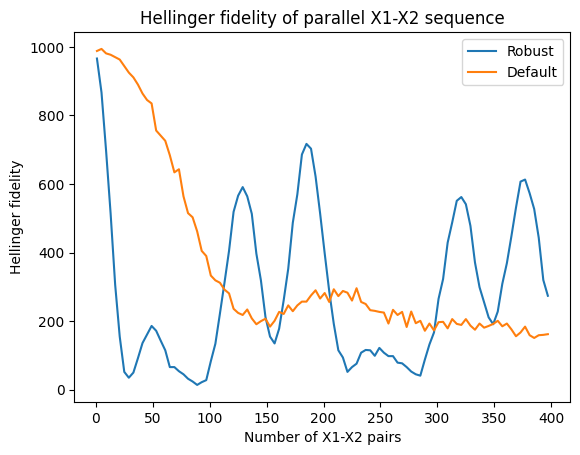

In [329]:
plt.plot([i + 1 for i in range(0, 400, 4)], robust_counts, label="Robust")
plt.plot([i + 1 for i in range(0, 400, 4)], default_counts, label="Default")
plt.title("Hellinger fidelity of parallel X1-X2 sequence")
plt.xlabel("Number of X1-X2 pairs")
plt.ylabel("Hellinger fidelity")
plt.legend()
plt.show();

Close the session whenever we are done submitting jobs to IBM.

In [122]:
session.cancel()
session.close()
session.status()

'Closed'